[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/01_linear_algebra.ipynb)

# 01 · Linear Algebra for Machine Learning

**Part 0 — Foundations** · Notebook 1 of 27

Machine learning is written in the language of linear algebra. Datasets are matrices, models multiply matrices, PCA and recommender systems are eigenvectors and SVDs, and a transformer is (mostly) a pile of matrix multiplications. This notebook builds the intuition **geometrically**: every matrix is a way of *moving space around*, and once you can see that, most of linear algebra becomes pictures.

**What you'll learn**

1. Data as vectors and matrices
2. Vectors, norms and the dot product (similarity)
3. Matrices as transformations of space
4. Matrix multiplication: three ways to see it
5. Special matrices: identity, diagonal, orthogonal, symmetric
6. Determinant, inverse, rank and null space (and why correlated features break regression)
7. Eigenvectors and eigenvalues
8. Symmetric and positive semi-definite matrices (bowls vs. saddles)
9. The singular value decomposition (SVD)
10. Low-rank approximation: compressing an image
11. Matrix calculus, and solving linear regression exactly

*Course map: CX 4240 Lecture 2 (Linear Algebra Revisit) and HW1 Q1 (PSD matrices); ISYE 4600 HW2 (correlated features, eigenfaces).*

In [1]:
#@title ⚙️ Setup — run this cell first (imports, plot style, helpers)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display, Markdown
import ipywidgets as widgets
from ipywidgets import interact, FloatSlider, IntSlider

# One consistent, colorblind-checked palette used across the whole series
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#4a3aa7", red="#e34948",
         ink="#0b0b0b", muted="#52514e", light="#d9d8d3")
plt.rcParams.update({
    "figure.figsize": (6.4, 4.2), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
        ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
    "lines.linewidth": 2, "font.size": 11, "legend.frameon": False,
    "animation.embed_limit": 40, "animation.frame_format": "jpeg",   # JPEG frames keep notebooks small
})

def show_anim(anim):
    """Render a matplotlib animation as an interactive player (play / pause / scrub)."""
    plt.close(anim._fig)
    return HTML(anim.to_jshtml(default_mode="once"))

rng = np.random.default_rng(0)
print("Setup complete ✓")

# Helpers for drawing vectors and transformed grids (used throughout this notebook)
def arrow(ax, v, color, label=None, origin=(0, 0), lw=2.5):
    o = np.asarray(origin, float); v = np.asarray(v, float)
    ax.annotate("", xy=o + v, xytext=o,
                arrowprops=dict(arrowstyle="-|>", color=color, lw=lw, mutation_scale=16))
    if label:
        ax.text(*(o + v * 1.08), label, color=color, fontsize=12, weight="bold", ha="center", va="center")

def draw_grid(ax, A=np.eye(2), lim=3.2, n=8, show_basis=True, square=True):
    """Draw the integer grid after it has been transformed by the 2×2 matrix A."""
    A = np.asarray(A, float)
    for k in range(-n, n + 1):
        for seg in (np.array([[k, -n], [k, n]]), np.array([[-n, k], [n, k]])):
            p = seg @ A.T
            ax.plot(p[:, 0], p[:, 1], color=C["blue"], alpha=0.25, lw=1)
    ax.axhline(0, color=C["muted"], lw=0.8); ax.axvline(0, color=C["muted"], lw=0.8)
    if square:
        sq = np.array([[0, 0], [1, 0], [1, 1], [0, 1]]) @ A.T
        ax.fill(sq[:, 0], sq[:, 1], color=C["yellow"], alpha=0.45)
    if show_basis:
        arrow(ax, A[:, 0], C["orange"], "î")
        arrow(ax, A[:, 1], C["aqua"], "ĵ")
    ax.set(xlim=(-lim, lim), ylim=(-lim, lim), aspect="equal")
    ax.grid(False)

print("Drawing helpers ready ✓")

Setup complete ✓
Drawing helpers ready ✓


---
## 1. Data *is* linear algebra

Before any math, here's why this matters. Almost every dataset in ML is stored as a **matrix** $X$ with one **row per example** and one **column per feature**:

$$X = \begin{bmatrix} — & x^{(1)\top} & — \\ — & x^{(2)\top} & — \\ & \vdots & \\ — & x^{(n)\top} & — \end{bmatrix} \in \mathbb{R}^{n \times d}$$

Each row $x^{(i)} \in \mathbb{R}^d$ is a **vector**: one example described by $d$ numbers. Images are matrices too. Here are both:

Feature matrix X (n=4 apartments × d=2 features):
 [[230.   1.]
 [506.   2.]
 [433.   2.]
 [190.   1.]] 



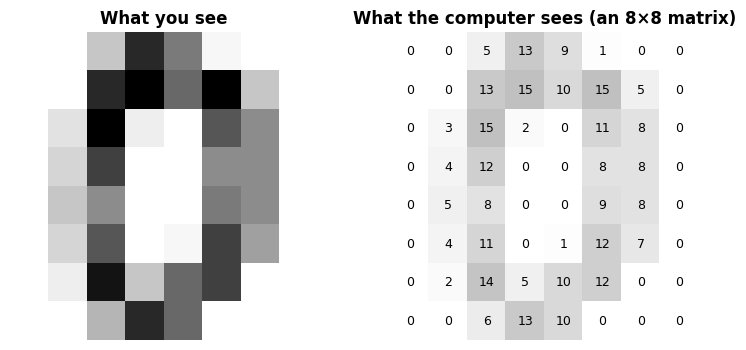

Flattened into a vector of length 64 → one row of a dataset matrix.


In [2]:
import pandas as pd
from sklearn.datasets import load_digits

# (a) The apartment table from CX 4240 Lecture 2, as a matrix
apartments = pd.DataFrame({"area_ft2": [230, 506, 433, 190], "bedrooms": [1, 2, 2, 1], "rent": [900, 1800, 1500, 800]})
X = apartments[["area_ft2", "bedrooms"]].to_numpy(float)
print("Feature matrix X (n=4 apartments × d=2 features):\n", X, "\n")

# (b) An 8×8 handwritten digit: an image is a matrix of pixel intensities
digit = load_digits().images[0]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 4))
ax1.imshow(digit, cmap="Greys")
ax1.set_title("What you see"); ax1.axis("off")
ax2.imshow(digit, cmap="Greys", alpha=0.25)
for (i, j), v in np.ndenumerate(digit):
    ax2.text(j, i, int(v), ha="center", va="center", fontsize=9)
ax2.set_title("What the computer sees (an 8×8 matrix)"); ax2.axis("off")
plt.show()
print("Flattened into a vector of length", digit.size, "→ one row of a dataset matrix.")

And a linear model's predictions for **every** example at once are a single matrix–vector product:

$$\hat{y} = X\theta \qquad \text{(n predictions} = (n\times d) \text{ matrix} \times (d\text{-vector)})$$

That's why GPUs, which are machines for multiplying matrices quickly, made deep learning possible.

---
## 2. Vectors

A vector $v \in \mathbb{R}^d$ is a list of $d$ numbers. You can picture it two ways:
- as a **point** in space (a data point), or
- as an **arrow** from the origin (a direction and a length).

Adding vectors means placing arrows tip to tail. Scaling a vector stretches it (and flips it if the scalar is negative).

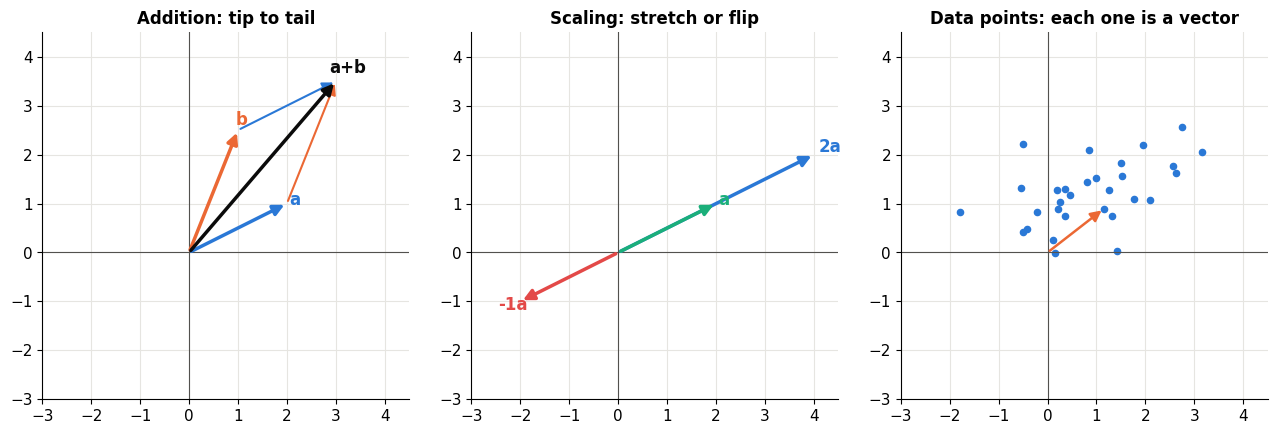

In [3]:
a, b = np.array([2.0, 1.0]), np.array([1.0, 2.5])
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax in axes:
    ax.axhline(0, color=C["muted"], lw=0.8); ax.axvline(0, color=C["muted"], lw=0.8)
    ax.set(xlim=(-3, 4.5), ylim=(-3, 4.5), aspect="equal")

ax = axes[0]
arrow(ax, a, C["blue"], "a"); arrow(ax, b, C["orange"], "b")
arrow(ax, b, C["orange"], origin=a, lw=1.5); arrow(ax, a, C["blue"], origin=b, lw=1.5)
arrow(ax, a + b, C["ink"], "a+b")
ax.set_title("Addition: tip to tail")

ax = axes[1]
for s, col in [(2, C["blue"]), (1, C["aqua"]), (-1, C["red"])]:
    arrow(ax, s * a, col, f"{s}a" if s != 1 else "a")
ax.set_title("Scaling: stretch or flip")

ax = axes[2]
pts = rng.normal(size=(30, 2)) * [1.2, 0.8] + [1, 1]
ax.scatter(*pts.T, color=C["blue"], s=20)
arrow(ax, pts[0], C["orange"], lw=1.8)
ax.set_title("Data points: each one is a vector")
fig.tight_layout(); plt.show()

### Norms: how long is a vector?

A **norm** $\|v\|$ measures a vector's size. The three you'll meet constantly:

| Norm | Formula | Name | Shows up in |
|---|---|---|---|
| $\ell_2$ | $\sqrt{\sum_i v_i^2}$ | Euclidean length | distances, MSE, Ridge regression |
| $\ell_1$ | $\sum_i \lvert v_i \rvert$ | Manhattan / taxicab | Lasso (sparsity!), robust losses |
| $\ell_\infty$ | $\max_i \lvert v_i \rvert$ | max norm | adversarial robustness |

The general **$\ell_p$ norm** is $\|v\|_p = \left(\sum_i |v_i|^p\right)^{1/p}$. A great way to see a norm is its **unit ball**: all vectors with $\|v\| \le 1$.

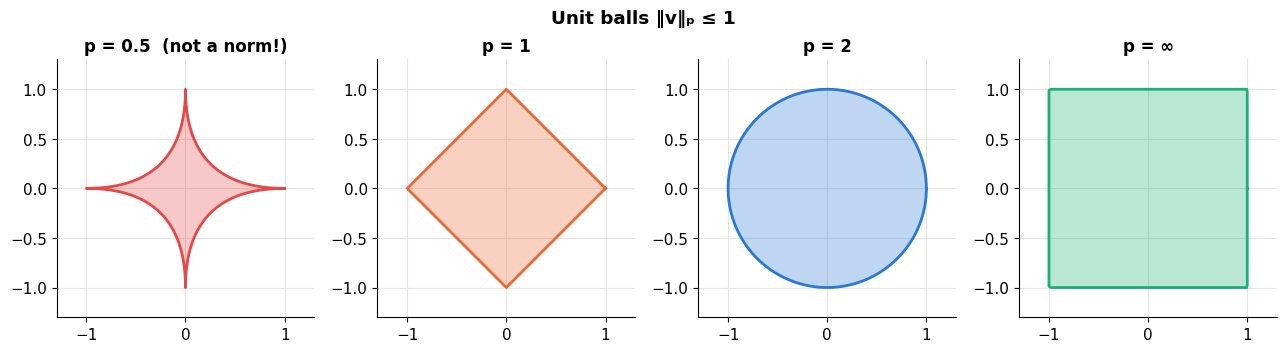

In [4]:
def unit_ball(p, num=400):
    t = np.linspace(0, 2 * np.pi, num)
    if np.isinf(p):
        x, y = np.cos(t), np.sin(t)
        s = np.maximum(np.abs(x), np.abs(y)); return x / s, y / s
    x = np.sign(np.cos(t)) * np.abs(np.cos(t)) ** (2 / p)
    y = np.sign(np.sin(t)) * np.abs(np.sin(t)) ** (2 / p)
    return x, y

fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
for ax, p, col in zip(axes, [0.5, 1, 2, np.inf], [C["red"], C["orange"], C["blue"], C["aqua"]]):
    ax.fill(*unit_ball(p), color=col, alpha=0.3); ax.plot(*unit_ball(p), color=col)
    ax.set(xlim=(-1.3, 1.3), ylim=(-1.3, 1.3), aspect="equal",
           title=f"p = {'∞' if np.isinf(p) else p}" + ("  (not a norm!)" if p < 1 else ""))
fig.suptitle("Unit balls ‖v‖ₚ ≤ 1", weight="bold"); fig.tight_layout(); plt.show()

🎚️ **Drag $p$** and watch the unit ball morph from a spiky star ($p<1$), to a diamond ($p=1$), a circle ($p=2$), and a square ($p\to\infty$).

In [5]:
def plot_ball(p=2.0):
    fig, ax = plt.subplots(figsize=(4.2, 4.2))
    x, y = unit_ball(p)
    ax.fill(x, y, color=C["blue"], alpha=0.25); ax.plot(x, y, color=C["blue"])
    ax.plot(*unit_ball(2), color=C["muted"], ls="--", lw=1, label="p = 2 for reference")
    ax.set(xlim=(-1.3, 1.3), ylim=(-1.3, 1.3), aspect="equal", title=f"‖v‖_{p:.2f} ≤ 1")
    ax.legend(loc="lower left", fontsize=8); plt.show()

interact(plot_ball, p=FloatSlider(value=2, min=0.3, max=10, step=0.1, description="p"));

> 🤔 **Question: Why does it matter that the $\ell_1$ ball has sharp corners?**
>
> This is the secret behind **Lasso** (notebook 07). When you minimize a loss subject to $\|\theta\|_1 \le t$, the loss contours usually first touch the diamond **at a corner**, and at a corner some coordinates are exactly zero. So $\ell_1$ regularization automatically sets useless feature weights to zero (feature selection), while $\ell_2$ (the round ball) only shrinks them. Keep this picture in mind.

> 🤔 **Question: Why is $p < 1$ "not a norm"?**
>
> A norm must satisfy the triangle inequality $\|a+b\| \le \|a\|+\|b\|$. For $p<1$ that fails, which you can see in the picture: the ball isn't **convex** (it caves inwards), so the straight line between two points in the ball leaves the ball.

---
## 3. The dot product: measuring similarity

The **dot product** has an algebraic definition and a geometric meaning, and the fact that they agree is one of the most useful facts in ML:

$$a \cdot b = a^\top b = \sum_{i} a_i b_i \;=\; \|a\|\,\|b\|\cos\theta$$

where $\theta$ is the angle between the vectors. So:
- **positive** → pointing roughly the same way,
- **zero** → perpendicular (**orthogonal**),
- **negative** → pointing in opposite directions.

Dividing out the lengths gives **cosine similarity**, $\cos\theta = \frac{a^\top b}{\|a\|\|b\|} \in [-1, 1]$, which only cares about direction.

The dot product also gives **projection**: the shadow of $b$ onto the direction of $a$ has length $\frac{a^\top b}{\|a\|}$.

🎚️ **Rotate $b$** and watch the dot product, the cosine and the projection (the green shadow).

In [6]:
def plot_dot(angle_deg=60, length_b=2.0):
    a = np.array([2.5, 0.8])
    ang = np.deg2rad(angle_deg) + np.arctan2(a[1], a[0])
    b = length_b * np.array([np.cos(ang), np.sin(ang)])
    proj = (a @ b) / (a @ a) * a
    fig, ax = plt.subplots(figsize=(5.5, 5))
    ax.axhline(0, color=C["muted"], lw=0.8); ax.axvline(0, color=C["muted"], lw=0.8)
    ax.plot([b[0], proj[0]], [b[1], proj[1]], ls=":", color=C["muted"])
    ax.plot([0, proj[0]], [0, proj[1]], color=C["aqua"], lw=6, alpha=0.6, solid_capstyle="butt", label="projection of b on a")
    arrow(ax, a, C["blue"], "a"); arrow(ax, b, C["orange"], "b")
    ax.set(xlim=(-3.2, 3.2), ylim=(-3.2, 3.2), aspect="equal")
    ax.set_title(f"a·b = {a @ b:+.2f}    cos θ = {a @ b / np.linalg.norm(a) / np.linalg.norm(b):+.2f}")
    ax.legend(loc="lower left", fontsize=9); plt.show()

interact(plot_dot,
         angle_deg=IntSlider(value=60, min=0, max=360, step=5, description="angle (°)"),
         length_b=FloatSlider(value=2, min=0.2, max=3, step=0.1, description="‖b‖"));

### Cosine similarity in action: which users have similar taste?

Here are 4 users' ratings (1–5) of 5 movies. Each user is a vector; cosine similarity tells us whose tastes point the same way. This is the core of **collaborative filtering** (notebook 17), and the same operation, a matrix of dot products, is the heart of **attention** in transformers (notebook 25).

,Avengers,John Wick,Notebook,Titanic,Inception
Ana,5,5,1,2,4
Ben,4,5,2,1,5
Cara,1,2,5,5,2
Dev,2,1,4,5,1


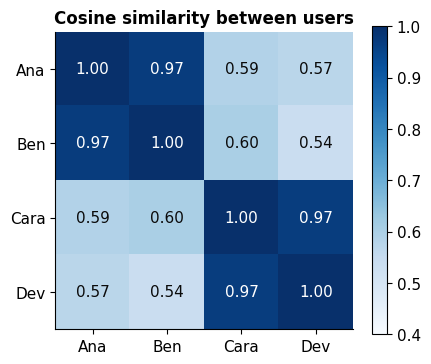

In [7]:
movies = ["Avengers", "John Wick", "Notebook", "Titanic", "Inception"]
R = pd.DataFrame([[5, 5, 1, 2, 4],
                  [4, 5, 2, 1, 5],
                  [1, 2, 5, 5, 2],
                  [2, 1, 4, 5, 1]], columns=movies, index=["Ana", "Ben", "Cara", "Dev"])
display(R)

U = R.to_numpy(float)
norms = np.linalg.norm(U, axis=1, keepdims=True)
cos_sim = (U @ U.T) / (norms @ norms.T)        # all pairwise dot products in ONE matrix multiply

fig, ax = plt.subplots(figsize=(4.8, 4))
im = ax.imshow(cos_sim, cmap="Blues", vmin=0.4, vmax=1)
ax.set_xticks(range(4), R.index); ax.set_yticks(range(4), R.index); ax.grid(False)
for (i, j), v in np.ndenumerate(cos_sim):
    ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if v > 0.8 else C["ink"])
ax.set_title("Cosine similarity between users"); plt.colorbar(im, ax=ax); plt.show()

---
> 🚧 **This notebook is being written section by section.** The sections above are complete and run top to bottom; more are on the way.